In [10]:
import sys
import os
import json
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

import geopandas as gpd


sys.path.append('../')
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [11]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [12]:
_id = 'xx7mqeiv'


In [14]:


model_dir = os.path.join('../models_trained', _id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


    


In [15]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['train', 'val'], config)
train_dl = dataloaders['train']
val_dl = dataloaders['val']

In [16]:
x,y = next(iter(train_dl))

In [17]:
type(x)

list

In [6]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()

In [7]:
#df = train_dataset.img_labels

#df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


1175506
cocoa


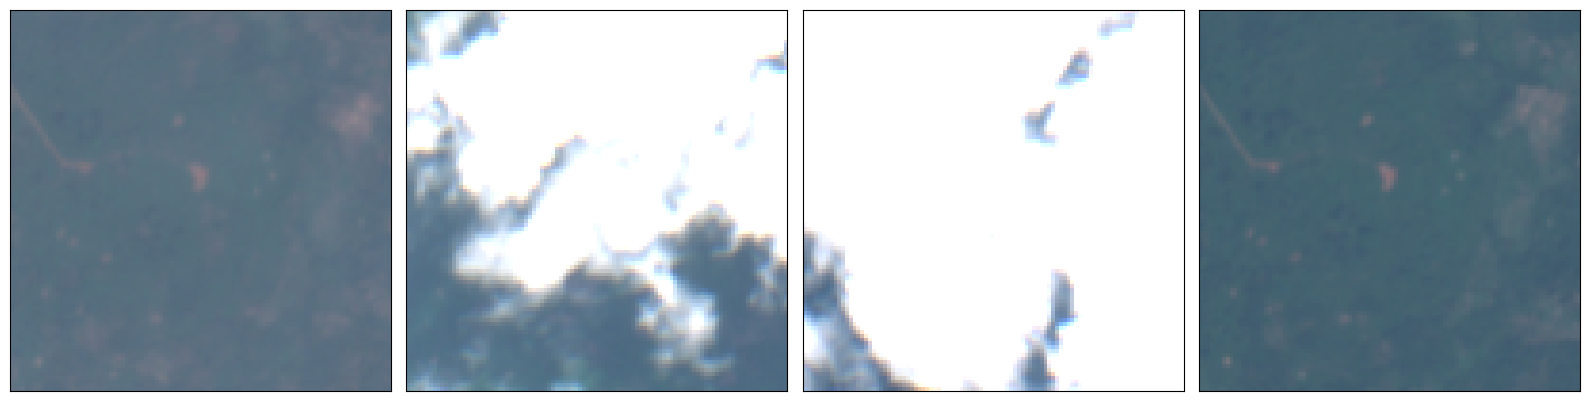

KeyboardInterrupt: Interrupted by user

In [8]:
dataset = val_dl.dataset

while True:

    i = random.randint(0,len(dataset.img_labels))
    #if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
    #    continue
    print(dataset.img_labels.iloc[i].sampleid)
    ts, label = train_dl.dataset.__getitem__(i)

    plot_images(ts, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [ ]:
sampleids = [
2040330, #forest plant. looks like palm oil
    5000927, #forest plant. looks like palm oil
    8118421,  #forest plant. looks like palm oil
]

In [21]:
train_dataset.img_labels.loc[train_dataset.img_labels.sampleid == 5002879]

,geometry,driver,sampleid,split
7438,POINT (105.97349049958846 14.335897554805385),shifting agriculture,5002879,train


## Visualize time series with TMF